# Mini Project: Reducing a CNN for TinyML using MNIST

**Part D — Question 23 (10 marks)**  
**Objective:** Train a small CNN to classify handwritten digits, reduce its model size using fewer filters and post-training INT8 quantization, and compare accuracy and model size.

This notebook is designed to run in Google Colab. It uses the MNIST dataset loaded directly through TensorFlow/Keras, so no manual dataset download is needed.

**Expected workflow**
1. Load and normalize MNIST.
2. Train a reference CNN.
3. Train a smaller CNN with fewer filters.
4. Convert the smaller CNN to a quantized TensorFlow Lite model.
5. Compare test accuracy and model size.
6. Visualize a few predictions and summarize the TinyML trade-off.



In [ ]:
from google.colab import drive
drive.mount('/content/drive')

## 1. Imports and reproducibility

In [1]:
import os
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from IPython.display import display

SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow version:", tf.__version__)
print("GPU available:", bool(tf.config.list_physical_devices("GPU")))

TensorFlow version: 2.21.0
GPU available: False


## 2. Load the dataset

MNIST contains 60,000 training images and 10,000 test images. Each image is a 28 × 28 grayscale image labelled as a digit from 0 to 9. Pixel values are normalized from 0–255 to 0–1.

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Training images: (60000, 28, 28, 1)
Training labels: (60000,)
Test images: (10000, 28, 28, 1)
Test labels: (10000,)


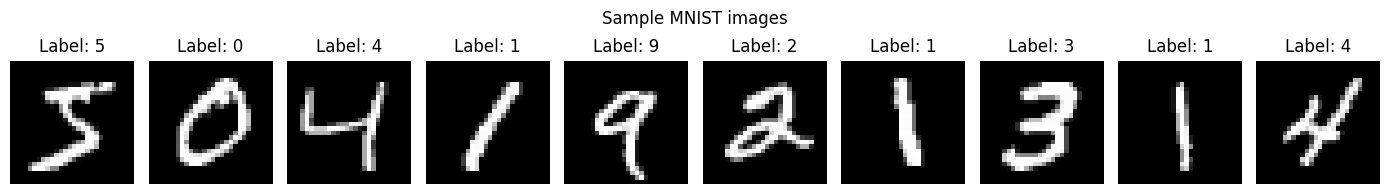

In [2]:
(x_train, y_train), (x_test, y_test) = tf.keras.datasets.mnist.load_data()

x_train = x_train.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

# CNN input shape: (height, width, channels)
x_train = x_train[..., np.newaxis]
x_test = x_test[..., np.newaxis]

print("Training images:", x_train.shape)
print("Training labels:", y_train.shape)
print("Test images:", x_test.shape)
print("Test labels:", y_test.shape)

fig, axes = plt.subplots(1, 10, figsize=(14, 2))
for i, ax in enumerate(axes):
    ax.imshow(x_train[i].squeeze(), cmap="gray")
    ax.set_title(f"Label: {y_train[i]}")
    ax.axis("off")
plt.suptitle("Sample MNIST images")
plt.tight_layout()
plt.show()

## 3. Build and train a reference CNN

This model uses more convolution filters than the compact model. A convolution layer learns visual patterns such as edges and strokes; pooling reduces the feature-map dimensions; the final dense layer predicts one of ten digits.

In [3]:
def build_reference_cnn():
    model = tf.keras.Sequential([
        tf.keras.layers.Input(shape=(28, 28, 1)),
        tf.keras.layers.Conv2D(16, kernel_size=3, activation="relu", padding="same"),
        tf.keras.layers.MaxPooling2D(pool_size=2),
        tf.keras.layers.Conv2D(32, kernel_size=3, activation="relu", padding="same"),
        tf.keras.layers.MaxPooling2D(pool_size=2),
        tf.keras.layers.Flatten(),
        tf.keras.layers.Dense(64, activation="relu"),
        tf.keras.layers.Dense(10, activation="softmax")
    ], name="reference_cnn")
    model.compile(
        optimizer="adam",
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )
    return model

reference_model = build_reference_cnn()
reference_model.summary()

start = time.time()
history_reference = reference_model.fit(
    x_train, y_train,
    epochs=3,
    batch_size=128,
    validation_split=0.1,
    verbose=1
)
reference_train_seconds = time.time() - start

reference_loss, reference_acc = reference_model.evaluate(x_test, y_test, verbose=0)
print(f"Reference CNN test accuracy: {reference_acc:.4f}")
print(f"Reference training time: {reference_train_seconds:.1f} seconds")

Model: "reference_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 28, 28, 16)     │           160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 14, 14, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 14, 14, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 7, 7, 32)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1568)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │       100,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 105,866 (413.54 KB)

 Trainable params: 105,866 (413.54 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/3
422/422 ━━━━━━━━━━━━━━━━━━━━ 31s 69ms/step - accuracy: 0.9179 - loss: 0.2839 - val_accuracy: 0.9810 - val_loss: 0.0698
Epoch 2/3
422/422 ━━━━━━━━━━━━━━━━━━━━ 29s 69ms/step - accuracy: 0.9762 - loss: 0.0762 - val_accuracy: 0.9858 - val_loss: 0.0517
Epoch 3/3
422/422 ━━━━━━━━━━━━━━━━━━━━ 41s 69ms/step - accuracy: 0.9827 - loss: 0.0554 - val_accuracy: 0.9885 - val_loss: 0.0444
Reference CNN test accuracy: 0.9838
Reference training time: 101.6 seconds


## 4. Build and train a compact CNN

The compact CNN uses fewer filters (8 and 16 instead of 16 and 32) and a smaller dense layer. This reduces the number of trainable parameters and can reduce memory use and inference cost, although accuracy may decrease.

In [4]:
def build_compact_cnn():
    model = tf.keras.Sequential([
        tf.keras.layers.Input(shape=(28, 28, 1)),
        tf.keras.layers.Conv2D(8, kernel_size=3, activation="relu", padding="same"),
        tf.keras.layers.MaxPooling2D(pool_size=2),
        tf.keras.layers.Conv2D(16, kernel_size=3, activation="relu", padding="same"),
        tf.keras.layers.MaxPooling2D(pool_size=2),
        tf.keras.layers.Flatten(),
        tf.keras.layers.Dense(32, activation="relu"),
        tf.keras.layers.Dense(10, activation="softmax")
    ], name="compact_cnn")
    model.compile(
        optimizer="adam",
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )
    return model

compact_model = build_compact_cnn()
compact_model.summary()

start = time.time()
history_compact = compact_model.fit(
    x_train, y_train,
    epochs=3,
    batch_size=128,
    validation_split=0.1,
    verbose=1
)
compact_train_seconds = time.time() - start

compact_loss, compact_acc = compact_model.evaluate(x_test, y_test, verbose=0)
print(f"Compact CNN test accuracy: {compact_acc:.4f}")
print(f"Compact training time: {compact_train_seconds:.1f} seconds")

Model: "compact_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_2 (Conv2D)               │ (None, 28, 28, 8)      │            80 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 14, 14, 8)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 14, 14, 16)     │         1,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 7, 7, 16)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 32)             │        25,120 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │           330 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 26,698 (104.29 KB)

 Trainable params: 26,698 (104.29 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/3
422/422 ━━━━━━━━━━━━━━━━━━━━ 23s 51ms/step - accuracy: 0.8757 - loss: 0.4255 - val_accuracy: 0.9652 - val_loss: 0.1259
Epoch 2/3
422/422 ━━━━━━━━━━━━━━━━━━━━ 20s 46ms/step - accuracy: 0.9608 - loss: 0.1260 - val_accuracy: 0.9748 - val_loss: 0.0857
Epoch 3/3
422/422 ━━━━━━━━━━━━━━━━━━━━ 21s 49ms/step - accuracy: 0.9725 - loss: 0.0903 - val_accuracy: 0.9802 - val_loss: 0.0715
Compact CNN test accuracy: 0.9781
Compact training time: 83.4 seconds


## 5. Convert the compact model to TensorFlow Lite with INT8 quantization

Post-training quantization represents many model weights and calculations with lower-precision integers. A representative sample is used to calibrate activation ranges. This notebook requests INT8 quantization for supported internal operations while retaining float input/output for easy evaluation in Colab.

In [5]:
# A small representative sample is enough for a quick demonstration.
def representative_dataset():
    for image in x_train[:500]:
        yield [np.expand_dims(image, axis=0).astype(np.float32)]

converter = tf.lite.TFLiteConverter.from_keras_model(compact_model)
converter.optimizations = [tf.lite.Optimize.DEFAULT]
converter.representative_dataset = representative_dataset
converter.target_spec.supported_ops = [tf.lite.OpsSet.TFLITE_BUILTINS_INT8]
# Keep model input/output as float32 so test images can be passed directly.
converter.inference_input_type = tf.float32
converter.inference_output_type = tf.float32

tflite_quantized_model = converter.convert()

os.makedirs("artifacts", exist_ok=True)
compact_model.save("artifacts/compact_cnn.keras")
with open("artifacts/compact_cnn_int8.tflite", "wb") as f:
    f.write(tflite_quantized_model)

print("Saved: artifacts/compact_cnn.keras")
print("Saved: artifacts/compact_cnn_int8.tflite")

Saved artifact at '/tmp/tmpfcx6p0ee'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 28, 28, 1), dtype=tf.float32, name='keras_tensor_8')
Output Type:
  TensorSpec(shape=(None, 10), dtype=tf.float32, name=None)
Captures:
  139673072427344: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139673072427536: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139673036989904: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139673036989712: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139673036990096: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139673036985680: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139673072419088: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139673072431760: TensorSpec(shape=(), dtype=tf.resource, name=None)


/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/convert.py:846: UserWarning: Statistics for quantized inputs were expected, but not specified; continuing anyway.
  warnings.warn(


Saved: artifacts/compact_cnn.keras
Saved: artifacts/compact_cnn_int8.tflite


## 6. Evaluate the quantized TensorFlow Lite model

The code below runs inference using the TensorFlow Lite interpreter and computes test accuracy. If conversion fails because of a runtime/version-specific TensorFlow Lite limitation, retain the trained compact CNN results and document the conversion error rather than claiming a quantized result.

In [6]:
interpreter = tf.lite.Interpreter(model_content=tflite_quantized_model)
interpreter.allocate_tensors()

input_details = interpreter.get_input_details()
output_details = interpreter.get_output_details()
print("TFLite input:", input_details[0]["shape"], input_details[0]["dtype"])
print("TFLite output:", output_details[0]["shape"], output_details[0]["dtype"])

tflite_predictions = []
for image in x_test:
    input_tensor = np.expand_dims(image, axis=0).astype(np.float32)
    interpreter.set_tensor(input_details[0]["index"], input_tensor)
    interpreter.invoke()
    output = interpreter.get_tensor(output_details[0]["index"])
    tflite_predictions.append(int(np.argmax(output[0])))

tflite_predictions = np.array(tflite_predictions)
tflite_acc = float(np.mean(tflite_predictions == y_test))
print(f"Quantized TFLite test accuracy: {tflite_acc:.4f}")

TFLite input: [ 1 28 28  1] <class 'numpy.float32'>
TFLite output: [ 1 10] <class 'numpy.float32'>


/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)


Quantized TFLite test accuracy: 0.9778


## 7. Compare accuracy, parameter count, and model file size

File size is a practical proxy for storage requirements, but it is not the same as peak RAM use or energy consumption. Those would need separate measurements on the target microcontroller.

Saved artifact at '/tmp/tmpwuetii28'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 28, 28, 1), dtype=tf.float32, name='keras_tensor_8')
Output Type:
  TensorSpec(shape=(None, 10), dtype=tf.float32, name=None)
Captures:
  139673072427344: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139673072427536: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139673036989904: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139673036989712: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139673036990096: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139673036985680: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139673072419088: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139673072431760: TensorSpec(shape=(), dtype=tf.resource, name=None)


,Model,Test accuracy,Parameters,File size (KB)
0,Reference CNN (Keras),0.9838,105866,1277.2012
1,Compact CNN (Keras),0.9781,26698,349.4561
2,Compact CNN (TFLite float32),0.9781,26698,108.6484
3,Compact CNN (TFLite quantized),0.9778,26698,32.9922


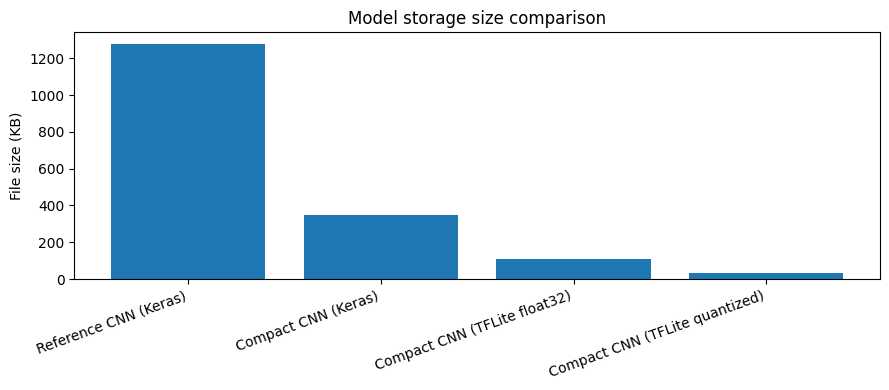

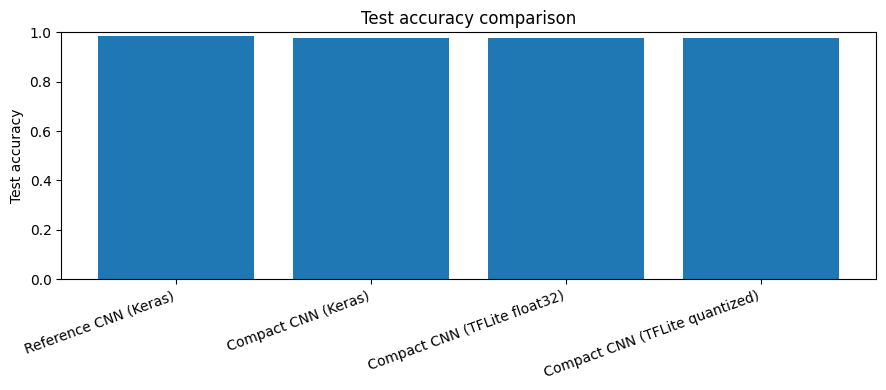

In [7]:
def model_file_size_bytes(path):
    return os.path.getsize(path)

reference_model.save("artifacts/reference_cnn.keras")
compact_model.save("artifacts/compact_cnn.keras")

# Save reference model as TFLite float32 for a more comparable deployment-file size.
float_converter = tf.lite.TFLiteConverter.from_keras_model(compact_model)
tflite_float_model = float_converter.convert()
with open("artifacts/compact_cnn_float32.tflite", "wb") as f:
    f.write(tflite_float_model)

results = pd.DataFrame([
    {
        "Model": "Reference CNN (Keras)",
        "Test accuracy": reference_acc,
        "Parameters": reference_model.count_params(),
        "File size (KB)": model_file_size_bytes("artifacts/reference_cnn.keras") / 1024
    },
    {
        "Model": "Compact CNN (Keras)",
        "Test accuracy": compact_acc,
        "Parameters": compact_model.count_params(),
        "File size (KB)": model_file_size_bytes("artifacts/compact_cnn.keras") / 1024
    },
    {
        "Model": "Compact CNN (TFLite float32)",
        "Test accuracy": compact_acc,
        "Parameters": compact_model.count_params(),
        "File size (KB)": len(tflite_float_model) / 1024
    },
    {
        "Model": "Compact CNN (TFLite quantized)",
        "Test accuracy": tflite_acc,
        "Parameters": compact_model.count_params(),
        "File size (KB)": len(tflite_quantized_model) / 1024
    }
])

display(results.round(4))

plt.figure(figsize=(9, 4))
plt.bar(results["Model"], results["File size (KB)"])
plt.ylabel("File size (KB)")
plt.title("Model storage size comparison")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()

plt.figure(figsize=(9, 4))
plt.bar(results["Model"], results["Test accuracy"])
plt.ylabel("Test accuracy")
plt.ylim(0, 1.0)
plt.title("Test accuracy comparison")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()

## 8. Inspect example predictions

Look for examples where the quantized model is incorrect. These examples can help explain the accuracy trade-off.

Number of TFLite misclassifications: 222


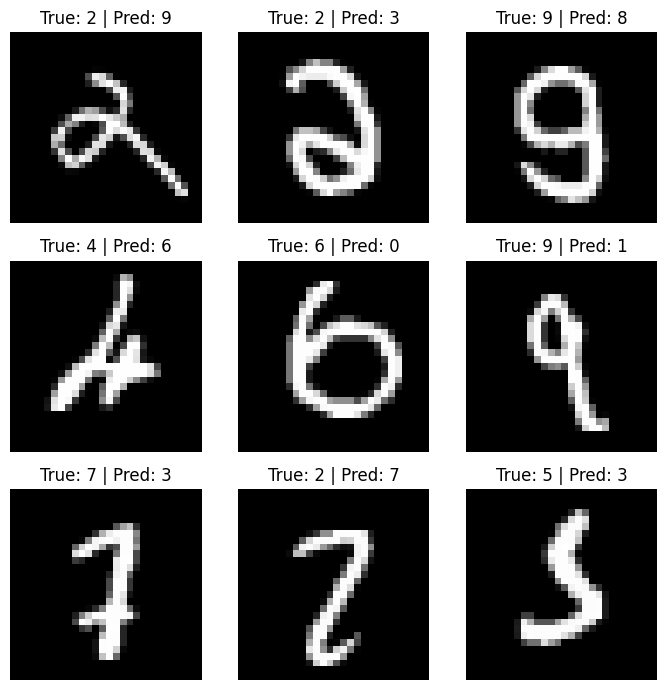

In [8]:
wrong_indices = np.where(tflite_predictions != y_test)[0]
print("Number of TFLite misclassifications:", len(wrong_indices))

if len(wrong_indices) > 0:
    selected = wrong_indices[:9]
else:
    selected = np.arange(9)

fig, axes = plt.subplots(3, 3, figsize=(7, 7))
for ax, idx in zip(axes.flat, selected):
    ax.imshow(x_test[idx].squeeze(), cmap="gray")
    ax.set_title(f"True: {y_test[idx]} | Pred: {tflite_predictions[idx]}")
    ax.axis("off")
plt.tight_layout()
plt.show()

## 9. Export the results for the report

This creates a CSV table of the metrics. Download it from the Colab file pane or use the optional download command below.

In [9]:
results.to_csv("artifacts/model_comparison.csv", index=False)
print("Metrics saved to artifacts/model_comparison.csv")

# Optional: download the CSV to your computer from Colab.
from google.colab import files
files.download("artifacts/model_comparison.csv")

Metrics saved to artifacts/model_comparison.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>